# 装箱拼图：把 12 种五格骨牌不重叠地装进箱子

## 这一章讲什么

要把 12 种[五格骨牌](https://en.wikipedia.org/wiki/Pentomino)(pentomino)不重叠、不留缝地装进一个形状固定的箱子。换成 CP-SAT 来做，需要的约束只有 `add_exactly_one()` 一种，条件全部由“恰好一个”来表达。

- 12 种骨牌，用字符的二维数组表示
- 旋转、翻转都试一遍，把能放的位置全部列出来
- 一边“每块骨牌放 1 处”，一边“每个格子放 1 块”，两种 `exactly_one` 一夹，答案就出来了

In [1]:
from ortools.sat.python import cp_model
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.cm import tab20
from matplotlib.collections import PatchCollection

## 12 种五格骨牌

五格骨牌，就是把 5 个正方形沿边连起来的形状(5 阶多格骨牌)。旋转过、翻过来的那些，长得一样的算同一种，归并起来正好 12 种。

图里 `*` 是方块，空格表示什么都没有。

In [2]:
pentominos = dict(
    F=[" **",
       "** ",
       " * "],
    P=["***",
       "** "],
    I=["*****"],
    N=["**  ",
       " ***"],
    L=["****",
       "   *"],
    T=["***",
       " * ",
       " * "],
    U=["* *",
       "***"],
    V=["*  ",
       "*  ",
       "***"],
    W=["*  ",
       "** ",
       " **"],
    X=[" * ",
       "***",
       " * "],
    Y=["  * ",
       "****"],
    Z=["** ",
       " * ",
       " **"],
)

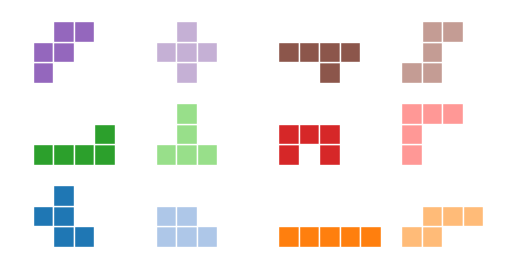

In [3]:
def as_array(block):
    """把字符列表变成 NumPy 的二维数组"""
    return np.array([list(row) for row in block])


def plot_pentominos(pentominos):
    """把 12 种并排画出来"""
    fig, ax = plt.subplots()
    ax.set_aspect('equal')
    rectangles = []
    for i, (name, block) in enumerate(pentominos.items()):
        r, c = np.where(block == '*')
        dx, dy = i % 4 * 6, i // 4 * 4
        for x, y in zip(c + dx, r + dy):
            rectangles.append(plt.Rectangle((x, y), 1, 1, facecolor=tab20.colors[i],
                                            edgecolor="white"))
    collection = PatchCollection(rectangles, match_original=True)
    ax.add_collection(collection)
    ax.autoscale_view()
    ax.axis('off')


pentominos_arr = {key: as_array(val) for key, val in pentominos.items()}
plot_pentominos(pentominos_arr)

`pentominos_arr['W']` 是一个二维数组，里面装的就是 `*` 和空格，形状与图上的 W 一一对应。

In [4]:
pentominos_arr['W']

array([['*', ' ', ' '],
       ['*', '*', ' '],
       [' ', '*', '*']], dtype='<U1')

## 箱子(棋盘)

箱子同样用二维数组表示，其中 `1` 是可以放骨牌的格子，`0` 则是一开始就空着、不用填的格子。

由于 12 块五格骨牌共 12 × 5 = 60 格，因此箱子的面积也得凑成 60 格，多一格少一格都不行。下面用到的 5 种箱子形状各不相同，面积都按这个数来算。

In [5]:
board1 = np.ones((8, 8), dtype=np.uint8)   # 64 - 4 = 60 格（中央空着）
board1[3:5, 3:5] = 0
board2 = np.ones((3, 20), dtype=np.uint8)
board3 = np.ones((4, 15), dtype=np.uint8)
board4 = np.ones((5, 12), dtype=np.uint8)
board5 = np.ones((6, 10), dtype=np.uint8)

boards = [board1, board2, board3, board4, board5]
print(board1)

[[1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 0 0 1 1 1]
 [1 1 1 0 0 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]]


## 列出能放的位置

一块骨牌能产生旋转 4 种 × 左右翻转 2 种 = 8 种朝向，每种朝向都往箱子里每个位置试一遍，放得下的就记下来，候选的数目就是这样累积起来的。

- `pentomino[:, ::step]` 在 `step=-1` 时做左右翻转
- `np.rot90(tile, r)` 把 90° 旋转做 `r` 次
- 落下去盖住的格子全是 `1`，这个位置就能放(超出箱子会抛 `IndexError`，跳过即可)

同一种摆法会被算出来好几次，因此先放进 `set` 去重，再用 `sorted()` 转回列表。

In [6]:
from itertools import product
from collections import defaultdict, namedtuple

Location = namedtuple('Location', 'pentomino cells')


def get_all_locations(pentominos, board):
    """列出 12 种骨牌所有能放的位置"""
    ymax, xmax = board.shape
    locations = set()

    for i, pentomino in enumerate(pentominos):
        for step in (1, -1):                      # 左右翻转
            flipped = pentomino[:, ::step]
            for r in range(4):                    # 旋转 90° × 4
                tile = np.rot90(flipped, r)
                locy, locx = np.where(tile == "*")
                for y, x in product(range(ymax), range(xmax)):
                    locy2 = locy + y
                    locx2 = locx + x
                    try:
                        if np.all(board[locy2, locx2] == 1):
                            cells = tuple(sorted(zip(locy2.tolist(), locx2.tolist())))
                            locations.add(Location(i, cells))
                    except IndexError:
                        pass                      # 超出了箱子
    return sorted(locations)


locations = get_all_locations(pentominos_arr.values(), boards[0])
print(len(locations), "种摆法")
for loc in locations[:5]:
    print(loc)

1568 种摆法
Location(pentomino=0, cells=((0, 0), (0, 1), (1, 1), (1, 2), (2, 1)))
Location(pentomino=0, cells=((0, 0), (1, 0), (1, 1), (1, 2), (2, 1)))
Location(pentomino=0, cells=((0, 1), (0, 2), (1, 0), (1, 1), (2, 1)))
Location(pentomino=0, cells=((0, 1), (0, 2), (1, 2), (1, 3), (2, 2)))
Location(pentomino=0, cells=((0, 1), (1, 0), (1, 1), (1, 2), (2, 0)))


## 求解

`locations` 里每个元素配一个布尔变量 `flag`，取 `True` 就表示在那个位置放这块骨牌。

约束只用 `add_exactly_one()`，一共两种，分别管骨牌与格子两个方向。

1. 每块骨牌 1 处：同一块骨牌不能占两个地方
2. 每个格子 1 块：一个格子不被两块骨牌同时占(反过来说，所有格子都得填满)

`pentomino_locations` 是“骨牌 → 它能放的位置编号”的字典，`cell_locations` 是“格子 → 包含这个格子的摆法编号”的字典。

In [7]:
def solve_board(board):
    """用 12 块五格骨牌把箱子装满"""
    locations = get_all_locations(pentominos_arr.values(), board)

    pentomino_locations = defaultdict(list)   # 骨牌 → 能放的位置编号
    cell_locations = defaultdict(list)        # 格子 → 包含该格子的摆法编号

    for idx, (tile_id, cells) in enumerate(locations):
        pentomino_locations[tile_id].append(idx)
        for cell in cells:
            cell_locations[cell].append(idx)

    model = cp_model.CpModel()
    flags = np.array([model.new_bool_var(f"b{i}") for i in range(len(locations))])

    # 每块骨牌 1 处，每个格子 1 块
    for d in (pentomino_locations, cell_locations):
        for index in d.values():
            model.add_exactly_one(flags[index].tolist())

    solver = cp_model.CpSolver()
    if solver.solve(model) not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        raise ValueError("没有找到解")

    return [locations[i].cells for i, flag in enumerate(flags) if solver.value(flag)]


def plot_solution(solution):
    """把解出的摆放画出来"""
    h, w = np.array(solution).reshape(-1, 2).max(axis=0) + 1
    fig, ax = plt.subplots(figsize=(w * 0.25, h * 0.25))
    ax.set_aspect('equal')

    rectangles = []
    for i, block in enumerate(solution):
        for y, x in block:
            rectangles.append(plt.Rectangle((x, y), 1, 1, facecolor=tab20.colors[i],
                                            edgecolor='white'))

    collection = PatchCollection(rectangles, match_original=True)
    ax.add_collection(collection)
    ax.autoscale_view()
    ax.invert_yaxis()
    ax.axis('off')
    return fig

5 种箱子，一个一个解过去，每解完一个就把摆放结果画出来。

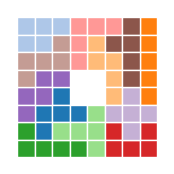

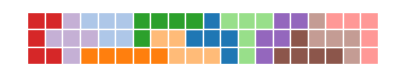

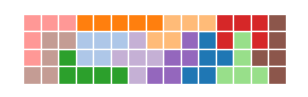

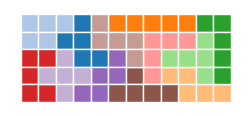

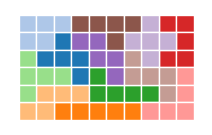

In [8]:
for board in boards:
    solution = solve_board(board)
    plot_solution(solution)

## 验算

解出来的摆法是否真的满足条件，还需要回头查验一遍，下面的检查只看两件事：每块骨牌是否都是 5 格，以及格子之间有没有重叠、有没有留下空隙。

In [9]:
def check_solution(board, solution):
    """每块骨牌都是 5 格，既没有重叠也没有空隙"""
    filled = {}
    for i, block in enumerate(solution):
        if len(block) != 5:
            return False, "有骨牌不是 5 格"
        for y, x in block:
            if (y, x) in filled:
                return False, f"格子 {(y, x)} 重叠了"
            filled[y, x] = i

    target = {(y, x) for y, x in zip(*np.where(board == 1))}
    if set(filled) != target:
        return False, "还有没填满的格子"
    return True, f"{len(solution)} 块骨牌把所有格子都填满了"


for board in boards:
    print(check_solution(board, solve_board(board)))

(True, '12 块骨牌把所有格子都填满了')


(True, '12 块骨牌把所有格子都填满了')


(True, '12 块骨牌把所有格子都填满了')


(True, '12 块骨牌把所有格子都填满了')


(True, '12 块骨牌把所有格子都填满了')


## 小结

- 摆五格骨牌这件事，靠“列出能放的位置”加“`add_exactly_one` 做选择”即可
- 旋转和翻转分别用 `np.rot90()` 和 `pentomino[:, ::-1]` 造，一共 8 种
- 重复的摆法先用 `set` 合起来，再转成列表
- 约束只有两种：骨牌那边放一个 `exactly_one`，格子那边再放一个，空隙和重叠就都没了